In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

In [ ]:
from google.colab import files

files.upload()

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle config set -n username -v haifasyn
!kaggle config set -n key -v d3ec5e90c70554157532eb299f73c163
# !kaggle datasets download -d

In [ ]:
import os

import kagglehub

# Set the path to the file you'd like to load
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

file_path = os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(file_path)
df.head()

Using Colab cache for faster access to the 'telco-customer-churn' dataset.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df = df.drop(["customerID"], axis=1)

In [ ]:
df.duplicated().sum()

np.int64(22)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
jumlah_error = df["TotalCharges"].isna().sum()
jumlah_error

np.int64(0)

In [ ]:
df.describe(include="all")

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7021,7021.000000,7021,7021,7021.000000,7021,7021,7021,7021,7021,7021,7021,7021,7021,7021,7021,7021,7021.000000,7021,7021
unique,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,3541,NaN,3619,4911,NaN,6339,3368,3090,3490,3080,3087,3465,2802,2777,3853,4161,2359,NaN,11,5164
mean,NaN,0.162512,NaN,NaN,32.469449,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.851894,NaN,NaN
std,NaN,0.368947,NaN,NaN,24.534965,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.069001,NaN,NaN
min,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.750000,NaN,NaN
50%,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.400000,NaN,NaN
75%,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.900000,NaN,NaN


In [ ]:
# baris_error = df[df['TotalCharges'].str.strip()=='']
# baris_error.head()
# df['TotalCharges'] = df['TotalCharges'].astype('float')

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
# df['SeniorCitizen'] = df['SeniorCitizen'].astype('str')

In [ ]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [ ]:
total_charges_mean = df["TotalCharges"].mean()
df["TotalCharges"] = df["TotalCharges"].fillna(total_charges_mean)
df["TotalCharges"].isna().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7021 non-null   object 
 1   SeniorCitizen     7021 non-null   int64  
 2   Partner           7021 non-null   object 
 3   Dependents        7021 non-null   object 
 4   tenure            7021 non-null   int64  
 5   PhoneService      7021 non-null   object 
 6   MultipleLines     7021 non-null   object 
 7   InternetService   7021 non-null   object 
 8   OnlineSecurity    7021 non-null   object 
 9   OnlineBackup      7021 non-null   object 
 10  DeviceProtection  7021 non-null   object 
 11  TechSupport       7021 non-null   object 
 12  StreamingTV       7021 non-null   object 
 13  StreamingMovies   7021 non-null   object 
 14  Contract          7021 non-null   object 
 15  PaperlessBilling  7021 non-null   object 
 16  PaymentMethod     7021 non-null   object 
 17  

## EDA

In [ ]:
print("Jumlah Gender laki-laki:", (df["gender"] == "Male").sum())
print("Jumlah Gender perempuan:", (df["gender"] == "Female").sum())

Jumlah Gender laki-laki: 3541
Jumlah Gender perempuan: 3480


In [ ]:
cat_columns = df.select_dtypes(exclude=["number"])
num_columns = df.select_dtypes(include=["number"])

In [ ]:
num_columns.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65


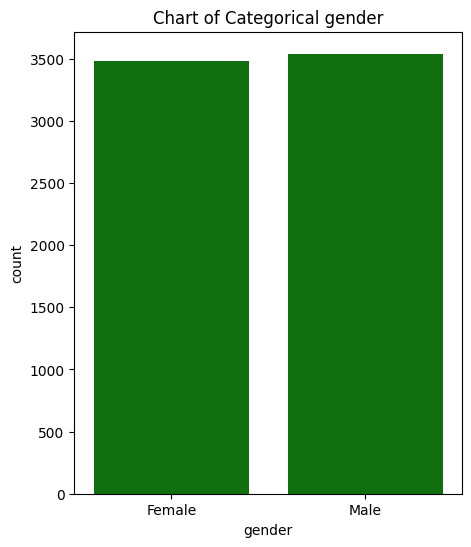

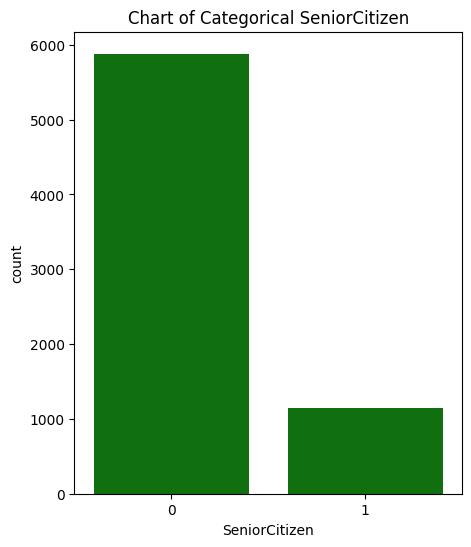

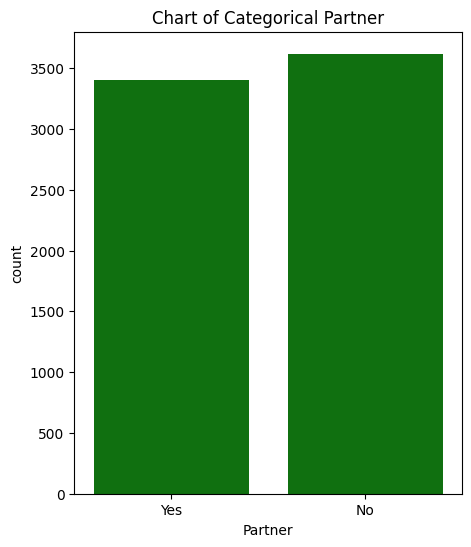

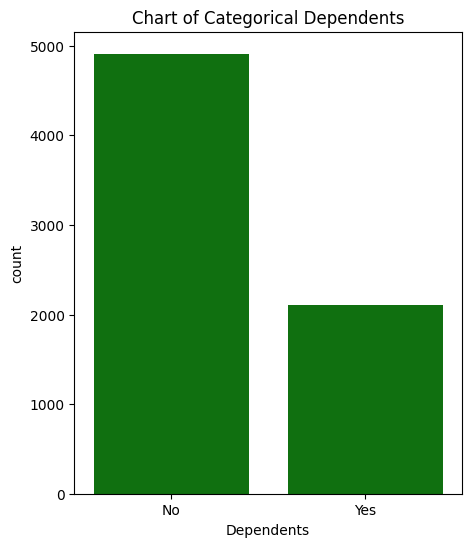

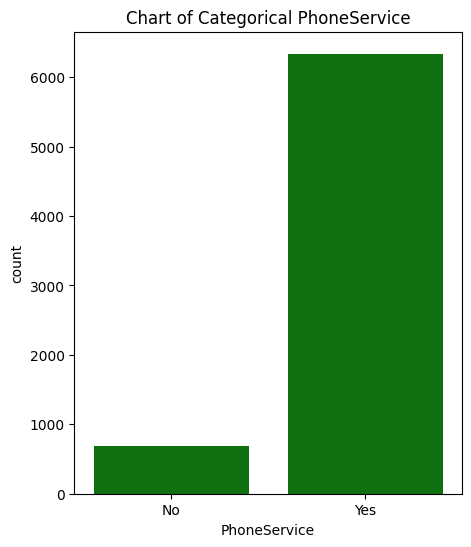

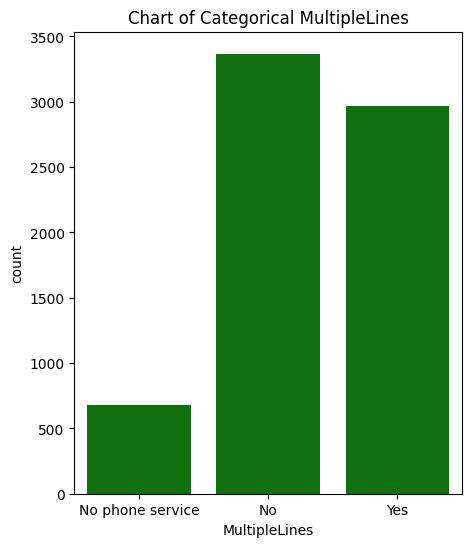

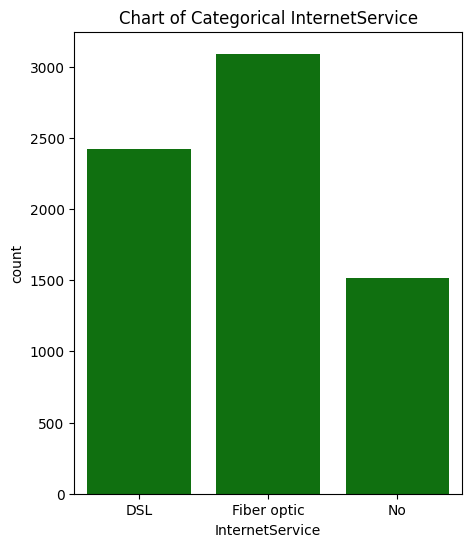

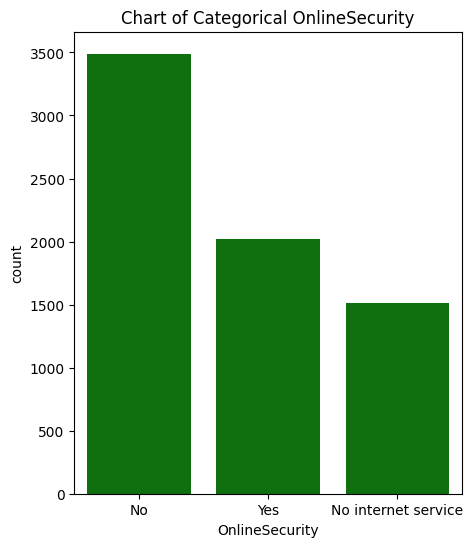

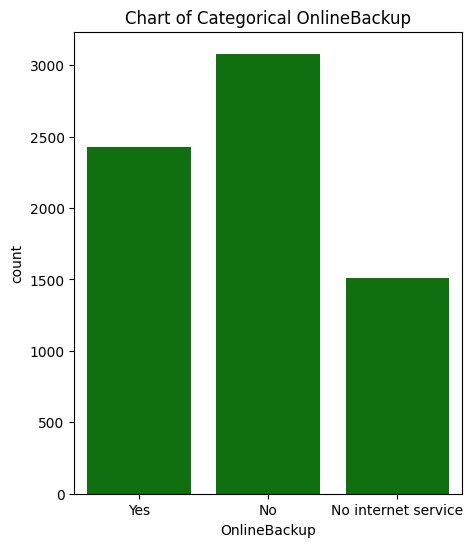

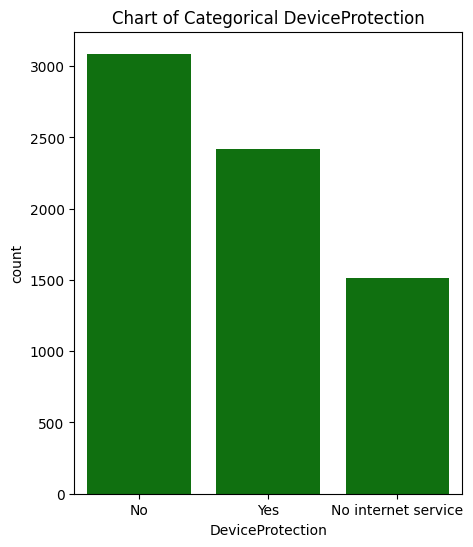

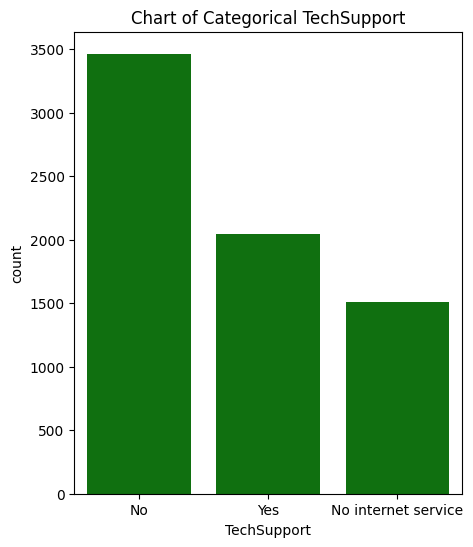

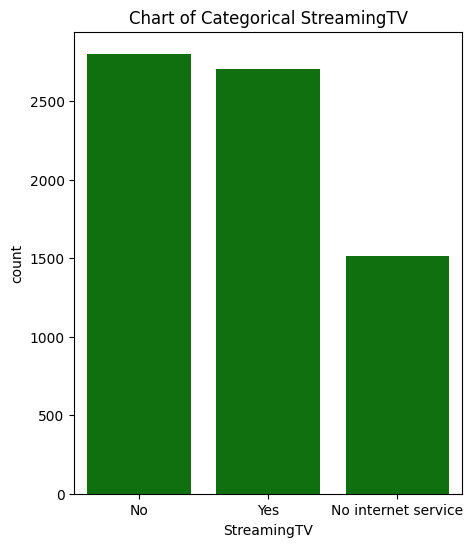

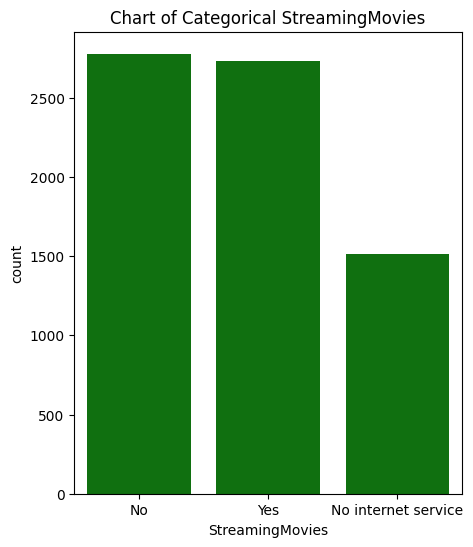

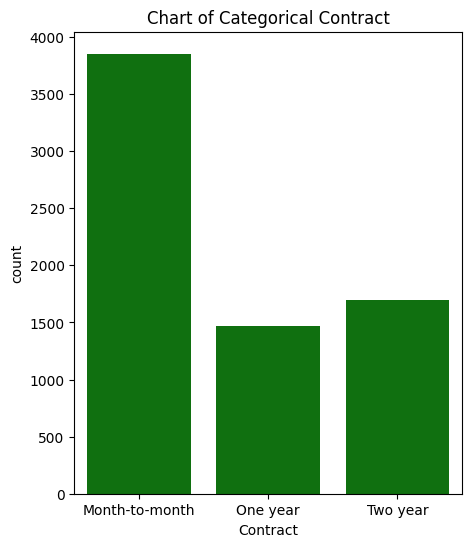

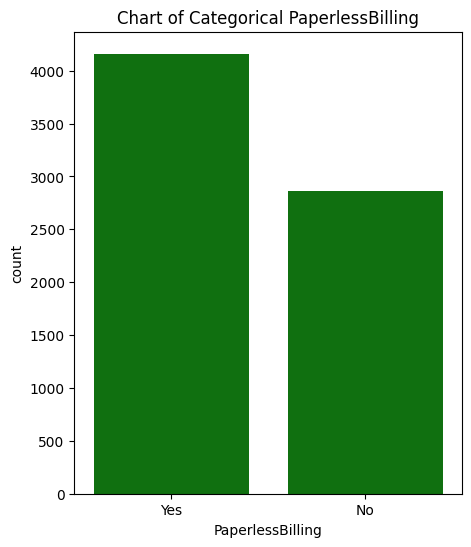

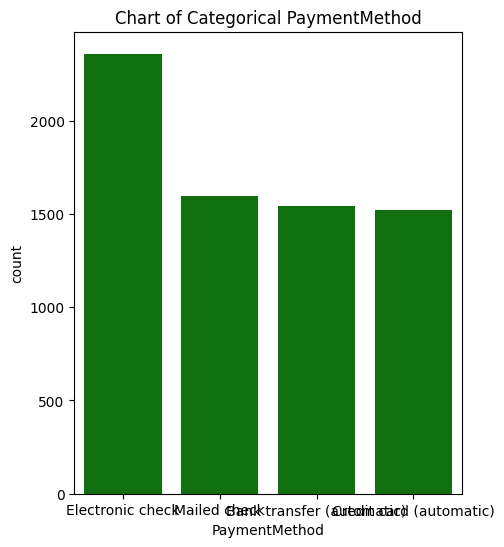

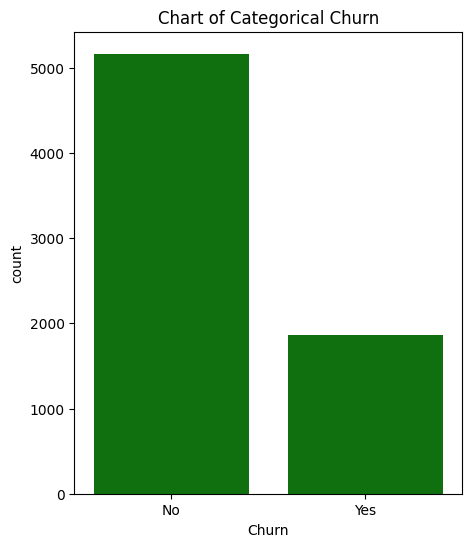

In [ ]:
for feature in cat_columns:
    plt.figure(figsize=(5, 6))
    sns.countplot(x=df[feature], data=df, color="green")
    plt.ylabel("count")
    # plt.xlabel(f"{feature}")
    plt.title(f"Chart of Categorical {feature}")
    plt.show()

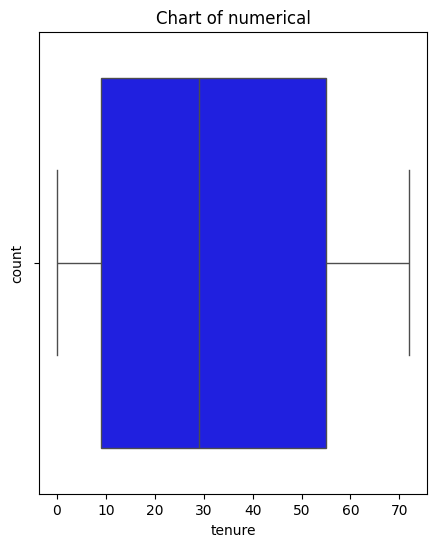

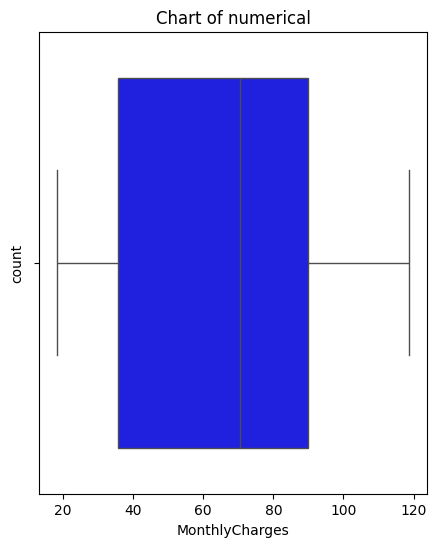

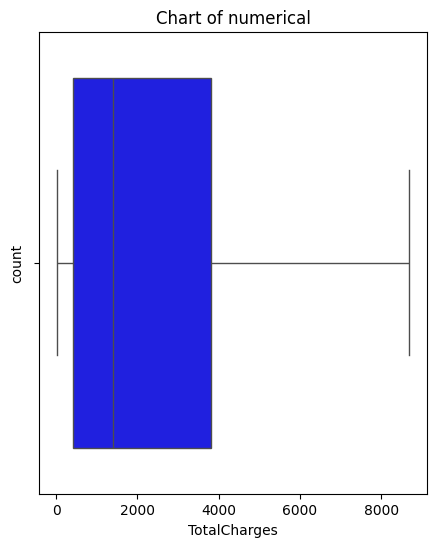

In [ ]:
for feature in num_columns:
    plt.figure(figsize=(5, 6))
    sns.boxplot(x=df[feature], data=df, color="blue")
    plt.ylabel("count")
    plt.xlabel(f"{feature}")
    plt.title("Chart of numerical")
    plt.show()

In [ ]:
df_corr = df.copy()

In [ ]:
# df_corr['Contract'].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

In [ ]:
df_corr["gender"] = df_corr["gender"].map({"Female": 1, "Male": 0})
df_corr["Partner"] = df_corr["Partner"].map({"Yes": 1, "No": 0})
df_corr["Dependents"] = df_corr["Dependents"].map({"Yes": 1, "No": 0})
df_corr["PhoneService"] = df_corr["PhoneService"].map({"Yes": 1, "No": 0})
df_corr["MultipleLines"] = df_corr["MultipleLines"].map(
    {"Yes": 1, "No": 0, "No phone service": 3}
)
df_corr["InternetService"] = df_corr["InternetService"].map(
    {"DSL": 1, "Fiber optic": 0, "No": 3}
)
df_corr["OnlineSecurity"] = df_corr["OnlineSecurity"].map(
    {"Yes": 1, "No": 0, "No internet service": 3}
)
df_corr["OnlineBackup"] = df_corr["OnlineBackup"].map(
    {"Yes": 1, "No": 0, "No internet service": 3}
)
df_corr["DeviceProtection"] = df_corr["DeviceProtection"].map(
    {"Yes": 1, "No": 0, "No internet service": 3}
)
df_corr["TechSupport"] = df_corr["TechSupport"].map(
    {"Yes": 1, "No": 0, "No internet service": 3}
)
df_corr["StreamingTV"] = df_corr["StreamingTV"].map(
    {"Yes": 1, "No": 0, "No internet service": 3}
)
df_corr["StreamingMovies"] = df_corr["StreamingMovies"].map(
    {"Yes": 1, "No": 0, "No internet service": 3}
)
df_corr["Contract"] = df_corr["Contract"].map(
    {"Month-to-month": 1, "One year": 0, "Two year": 3}
)
df_corr["PaperlessBilling"] = df_corr["PaperlessBilling"].map({"Yes": 1, "No": 0})
df_corr["PaymentMethod"] = df_corr["PaymentMethod"].map(
    {
        "Electronic check": 1,
        "Mailed check": 0,
        "Bank transfer (automatic)": 3,
        "Credit card (automatic)": 4,
    }
)
df_corr["Churn"] = df_corr["Churn"].map({"Yes": 1, "No": 0})

In [ ]:
df_corr.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1,0,1,0,1,0,3,1,0,1,0,0,0,0,1,1,1,29.85,29.85,0
1,0,0,0,0,34,1,0,1,1,0,1,0,0,0,0,0,0,56.95,1889.50,0
2,0,0,0,0,2,1,0,1,1,1,0,0,0,0,1,1,0,53.85,108.15,1
3,0,0,0,0,45,0,3,1,1,0,1,1,0,0,0,0,3,42.30,1840.75,0
4,1,0,0,0,2,1,0,0,0,0,0,0,0,0,1,1,1,70.70,151.65,1


In [ ]:
df_corr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7021 non-null   int64  
 1   SeniorCitizen     7021 non-null   int64  
 2   Partner           7021 non-null   int64  
 3   Dependents        7021 non-null   int64  
 4   tenure            7021 non-null   int64  
 5   PhoneService      7021 non-null   int64  
 6   MultipleLines     7021 non-null   int64  
 7   InternetService   7021 non-null   int64  
 8   OnlineSecurity    7021 non-null   int64  
 9   OnlineBackup      7021 non-null   int64  
 10  DeviceProtection  7021 non-null   int64  
 11  TechSupport       7021 non-null   int64  
 12  StreamingTV       7021 non-null   int64  
 13  StreamingMovies   7021 non-null   int64  
 14  Contract          7021 non-null   int64  
 15  PaperlessBilling  7021 non-null   int64  
 16  PaymentMethod     7021 non-null   int64  
 17  

<Axes: >

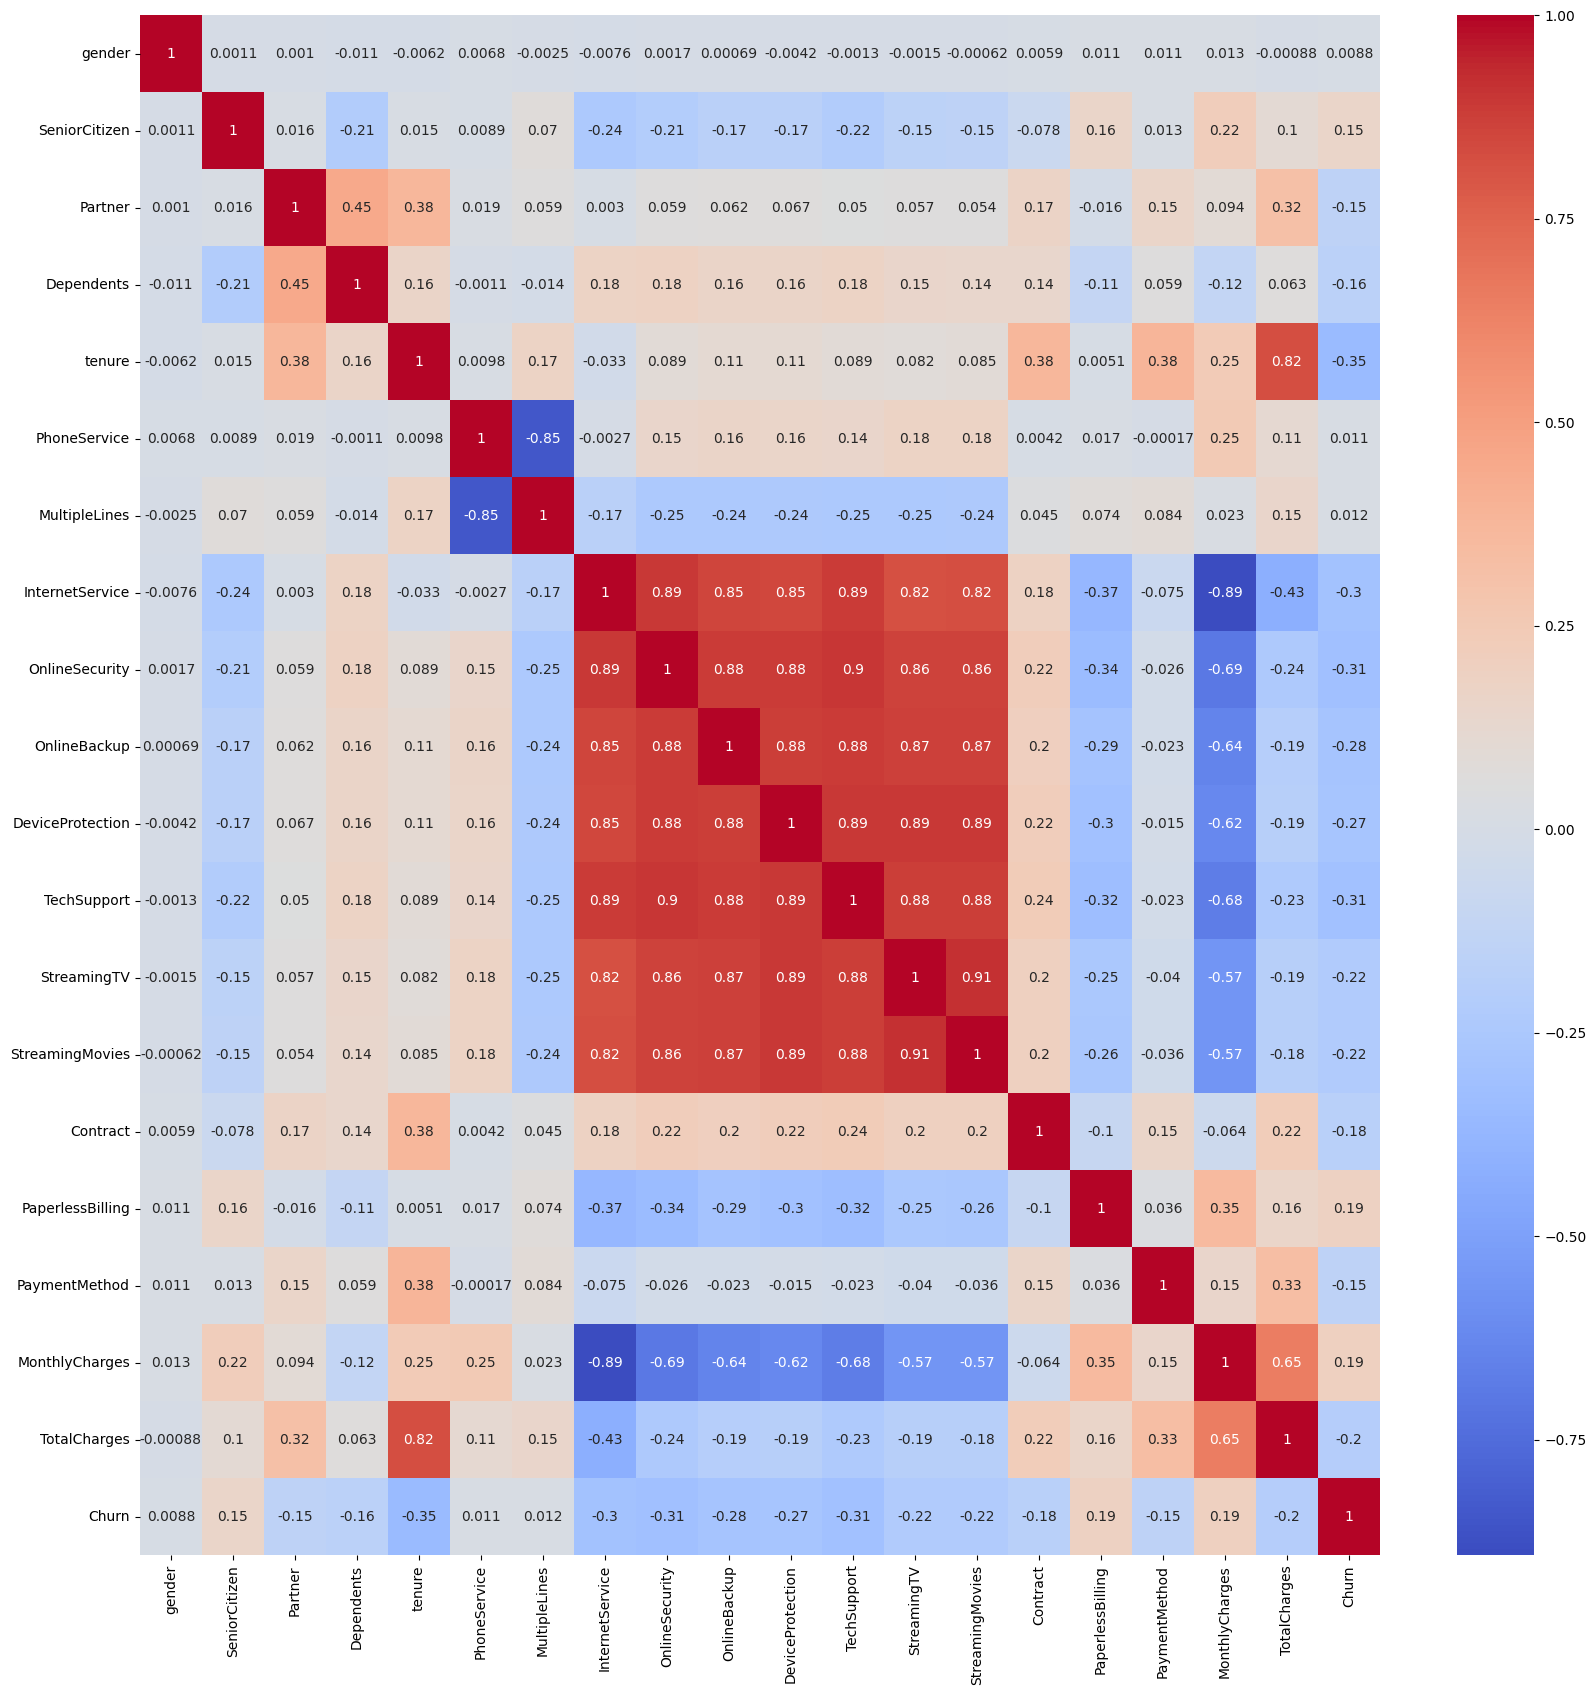

In [ ]:
plt.figure(figsize=(20, 20))
sns.heatmap(df_corr.corr(), cmap="coolwarm", annot=True)

PaymentMethod, gender, PhoneService, MultipleLines

# Cleaning

In [ ]:
df_clean = df.copy().drop(columns=["gender", "PhoneService", "MultipleLines"])

In [ ]:
df_clean.head()

,SeniorCitizen,Partner,Dependents,tenure,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Yes,No,1,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,0,No,No,34,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,0,No,No,2,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,0,No,No,45,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,0,No,No,2,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SeniorCitizen     7021 non-null   int64  
 1   Partner           7021 non-null   object 
 2   Dependents        7021 non-null   object 
 3   tenure            7021 non-null   int64  
 4   InternetService   7021 non-null   object 
 5   OnlineSecurity    7021 non-null   object 
 6   OnlineBackup      7021 non-null   object 
 7   DeviceProtection  7021 non-null   object 
 8   TechSupport       7021 non-null   object 
 9   StreamingTV       7021 non-null   object 
 10  StreamingMovies   7021 non-null   object 
 11  Contract          7021 non-null   object 
 12  PaperlessBilling  7021 non-null   object 
 13  PaymentMethod     7021 non-null   object 
 14  MonthlyCharges    7021 non-null   float64
 15  TotalCharges      7021 non-null   float64
 16  Churn             7021 non-null   object 
dtype

Encode

In [ ]:
df_clean = pd.get_dummies(
    df_clean, columns=["InternetService", "Contract", "PaymentMethod"], dtype="int64"
).reset_index(drop=True)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7021 entries, 0 to 7020
Data columns (total 24 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   SeniorCitizen                            7021 non-null   int64  
 1   Partner                                  7021 non-null   object 
 2   Dependents                               7021 non-null   object 
 3   tenure                                   7021 non-null   int64  
 4   OnlineSecurity                           7021 non-null   object 
 5   OnlineBackup                             7021 non-null   object 
 6   DeviceProtection                         7021 non-null   object 
 7   TechSupport                              7021 non-null   object 
 8   StreamingTV                              7021 non-null   object 
 9   StreamingMovies                          7021 non-null   object 
 10  PaperlessBilling                         7021 no

In [ ]:
le = LabelEncoder()

cat_cols = df_clean.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
    df_clean[col] = le.fit_transform(df_clean[col])

df_clean.head()

,SeniorCitizen,Partner,Dependents,tenure,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,1,0,2,0,0,0,0,...,1,0,0,1,0,0,0,0,1,0
1,0,0,0,34,2,0,2,0,0,0,...,1,0,0,0,1,0,0,0,0,1
2,0,0,0,2,2,2,0,0,0,0,...,1,0,0,1,0,0,0,0,0,1
3,0,0,0,45,2,0,2,2,0,0,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,2,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0


In [ ]:
X = df_clean.drop("Churn", axis=1)
y = df_clean["Churn"]

In [ ]:
from collections import Counter

from imblearn.over_sampling import SMOTE

print("Distribusi kelas sebelum SMOTE:", Counter(y))

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("Distribusi kelas setelah SMOTE:", Counter(y_resampled))

Distribusi kelas sebelum SMOTE: Counter({0: 5164, 1: 1857})
Distribusi kelas setelah SMOTE: Counter({0: 5164, 1: 5164})


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((8262, 23), (2066, 23), (8262,), (2066,))

In [ ]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [ ]:
X_train.head()

,SeniorCitizen,Partner,Dependents,tenure,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
9032,0,1,0,1.235226,1,1,2,0,0,2,...,0,0,0,0,0,0,0,0,0,0
8101,0,0,0,0.648555,1,0,0,0,0,2,...,0,1,0,1,0,0,0,0,1,0
8401,0,0,0,-0.985743,0,0,0,0,1,0,...,0,1,0,1,0,0,0,0,0,0
828,0,1,1,1.360941,0,2,2,0,2,0,...,0,1,0,0,1,0,0,0,1,0
6965,1,0,0,0.313314,2,2,2,0,2,2,...,0,1,0,0,1,0,0,0,1,0


In [ ]:
train_data = X_train.copy()

train_data["Churn"] = y_train
data_corr = train_data.corr()

<Axes: >

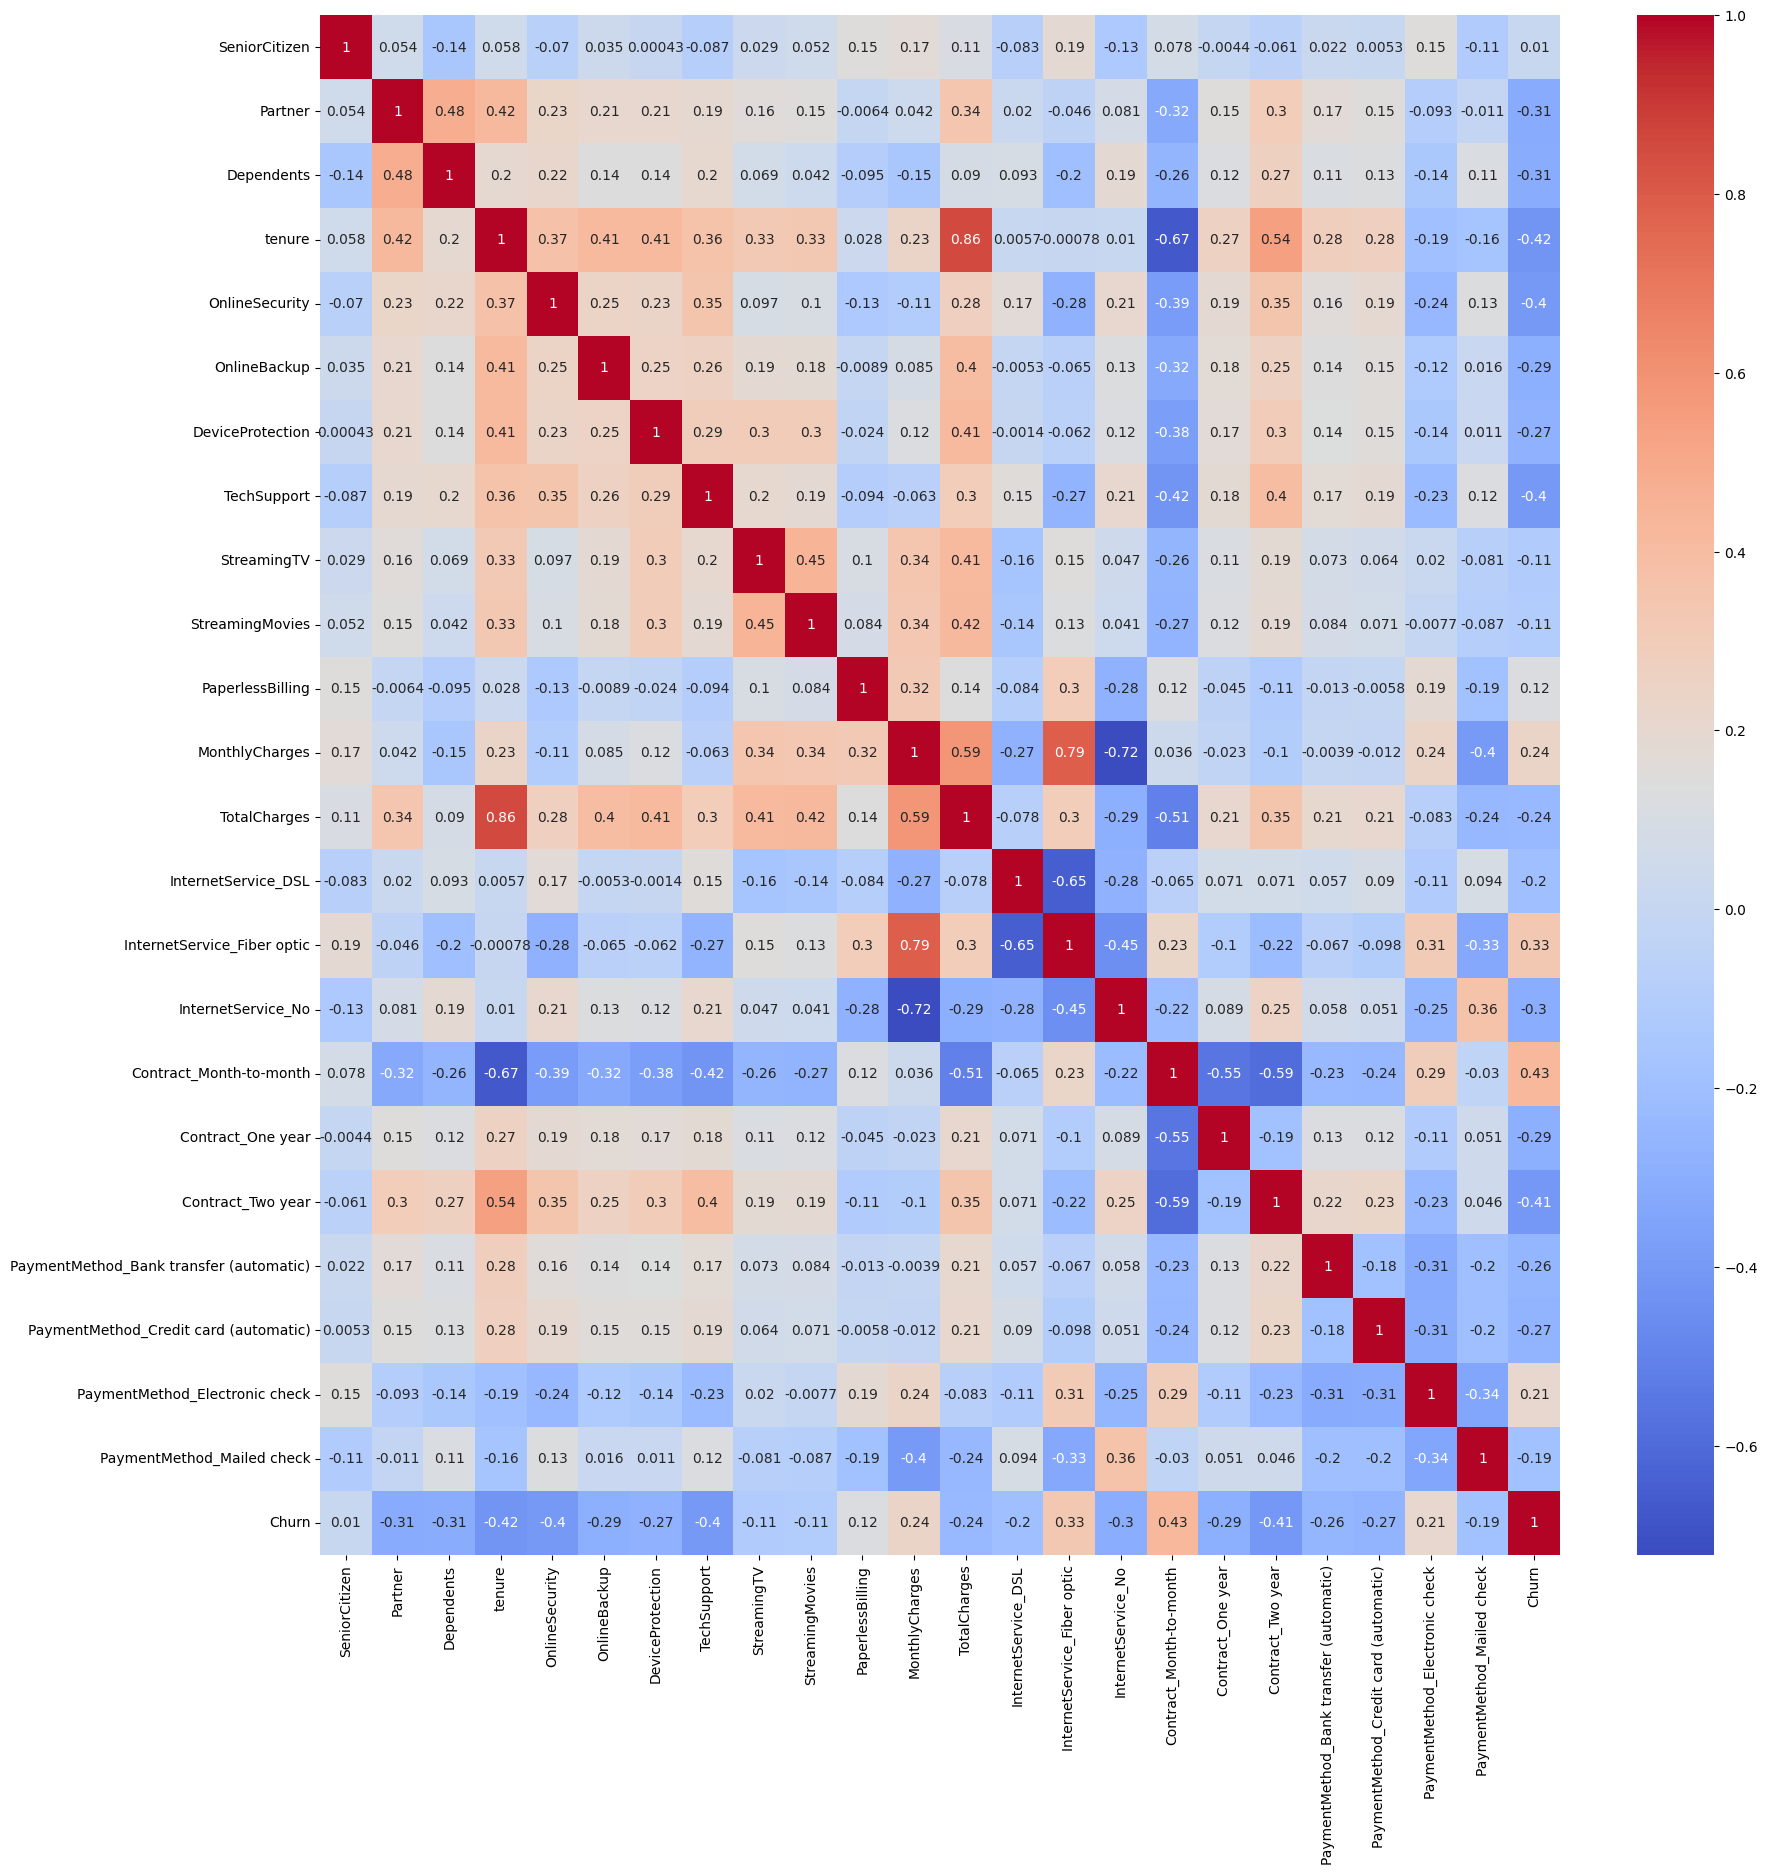

In [ ]:
plt.figure(figsize=(20, 20))
sns.heatmap(data_corr, cmap="coolwarm", annot=True)

Modeling

In [ ]:
models = {
    "KNN": KNeighborsClassifier(random_state=42),
    "RF": RandomForestClassifier(random_state=42),
    "XBoost": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(random_state=42),
}

In [ ]:
rf = RandomForestClassifier(random_state=42)


param_grid = {
    "n_estimators": [10, 50, 100, 200],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
}

grid_search = GridSearchCV(
    param_grid=param_grid, estimator=rf, cv=5, n_jobs=-1, verbose=2, scoring="accuracy"
)


grid_search.fit(X_train, y_train)

print("\n --Hasil Grid Search--")
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits

 --Hasil Grid Search--
Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}
Best Score: 0.8540317772807237


In [ ]:
knn = KNeighborsClassifier()
param_grid_knn = {
    "n_neighbors": [3, 5, 7],
    "weights": ["uniform", "distance"],
    "leaf_size": [10, 20, 30],
    "p": [1, 2],
    "algorithm": ["auto", "ball_tree", "kd_tree", "brute"],
    "metric": ["minkowski", "manhattan", "euclidean"],
}

gs_knn = GridSearchCV(
    param_grid=param_grid_knn, estimator=knn, n_jobs=None, verbose=2, scoring="accuracy"
)

gs_knn.fit(X_train, y_train)


print("\n --Hasil Grid Search KNN--")
print("Best Parameters:", gs_knn.best_params_)
print("Best Score:", gs_knn.best_score_)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
[CV] END algorithm=auto, leaf_size=10, metric=minkowski, n_neighbors=3, p=1, weights=uniform; total time=   1.0s
[CV] END algorithm=auto, leaf_size=10, metric=minkowski, n_neighbors=3, p=1, weights=uniform; total time=   0.8s
[CV] END algorithm=auto, leaf_size=10, metric=minkowski, n_neighbors=3, p=1, weights=uniform; total time=   0.5s
[CV] END algorithm=auto, leaf_size=10, metric=minkowski, n_neighbors=3, p=1, weights=uniform; total time=   0.5s
[CV] END algorithm=auto, leaf_size=10, metric=minkowski, n_neighbors=3, p=1, weights=uniform; total time=   0.5s
[CV] END algorithm=auto, leaf_size=10, metric=minkowski, n_neighbors=3, p=1, weights=distance; total time=   0.5s
[CV] END algorithm=auto, leaf_size=10, metric=minkowski, n_neighbors=3, p=1, weights=distance; total time=   0.5s
[CV] END algorithm=auto, leaf_size=10, metric=minkowski, n_neighbors=3, p=1, weights=distance; total time=   0.5s
[CV] END algorithm=auto, leaf

In [ ]:
xgboost = GradientBoostingClassifier()
param_grid_xgboost = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.1, 0.2],
    "max_depth": [3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "loss": ["log_loss", "exponential"],
    "criterion": ["friendman_mse", "squared_error"],
    "max_features": ["sqrt", "log2", None],
}

gs_xgboost = GridSearchCV(
    param_grid=param_grid_xgboost,
    estimator=xgboost,
    n_jobs=None,
    verbose=2,
    scoring="accuracy",
)

gs_xgboost.fit(X_train, y_train)


print("\n --Hasil Grid Search XGBoost--")
print("Best Parameters:", gs_xgboost.best_params_)
print("Best Score:", gs_xgboost.best_score_)

Streaming output truncated to the last 5000 lines.
[CV] END criterion=friendman_mse, learning_rate=0.1, loss=log_loss, max_depth=4, max_features=None, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   0.0s
[CV] END criterion=friendman_mse, learning_rate=0.1, loss=log_loss, max_depth=4, max_features=None, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   0.0s
[CV] END criterion=friendman_mse, learning_rate=0.1, loss=log_loss, max_depth=4, max_features=None, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   0.0s
[CV] END criterion=friendman_mse, learning_rate=0.1, loss=log_loss, max_depth=4, max_features=None, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   0.0s
[CV] END criterion=friendman_mse, learning_rate=0.1, loss=log_loss, max_depth=4, max_features=None, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.0s
[CV] END criterion=friendman_mse, learning_rate=0.1, loss=

KeyboardInterrupt: 

In [ ]:
best_model = grid_search.best_estimator_
test_accuracy = grid_search.score(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Accuracy: 0.7851


In [ ]:
summary = []

for names, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    recall = recall_score(y_test, preds)
    # f1=f1_score(y_test, preds)

    summary.append(
        {"Model": names, "Accuracy": acc, "Precision": prec, "Recall": recall}
    )
    summary_df = pd.DataFrame(summary)

print("\n Model Evaluation Summary:")
summary_df


 Model Evaluation Summary:


,Model,Accuracy,Precision,Recall
0,KNN,0.760142,0.523364,0.477273
1,RF,0.755872,0.514019,0.468750
2,XBoost,0.780783,0.569620,0.511364
3,SVM,0.777936,0.569930,0.463068
